# Detección de anomalías en videos de vigilancia (detección binaria)

Versión simplificada del proyecto: el modelo indica **en qué segmentos del video ocurre una anomalía**, sin identificar personas ni el tipo de evento.

Pipeline: video → features CLIP por fragmento de 16 frames → modelo temporal (Transformer, MIL) → puntuación de anomalía por fragmento → umbral y post-procesado → intervalos anómalos y video MP4 anotado.

Antes de ejecutar, edita la celda **1.2** (entorno y rutas). El notebook corre en local o en Google Colab. Con `TEST_MODE = True` todo corre con datos sintéticos.

## 1. Configuración

In [64]:
# 1.1 Install libraries
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch", "decord"], check=False)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


CompletedProcess(args=['/mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/.venv/bin/python', '-m', 'pip', 'install', '-q', 'open_clip_torch', 'decord'], returncode=0)

In [65]:
# 1.2 User parameters
ENVIRONMENT = "local"          # "local" | "colab"
TEST_MODE = False              # True: synthetic data to test the pipeline

# Local paths (searched recursively; may point to the same folder or be lists)
BASE = "."
LOCAL_PATHS = {
    "videos":   f"{BASE}/archive/UCF_Crimes/UCF_Crimes/Videos",   # UCF-Crime and demo .mp4 files
    "uca":      "",                                               # no local UCA: cloned from GitHub
    "features": f"{BASE}/UCFClipFeatures",                        # VadCLIP .npy files
    "lists":    f"{BASE}/VadCLIP-main/list",                      # Anomaly_Train/Test and Temporal_Anomaly_Annotation
    "work":     f"{BASE}/trabajo",                                # intermediate results
}
COLAB_PATHS = {"videos": "/content/drive/MyDrive/UCF-Crime", "uca": "",
               "features": "/content/drive/MyDrive/UCFClipFeatures",
               "lists": "", "work": "/content/drive/MyDrive/vad_trabajo"}
MOUNT_DRIVE = True             # Colab only
WORK_SUBDIR = "binario"        # outputs go to <work>/binario (keeps the previous notebook's results apart)

DEMO_VIDEOS = []               # video paths for the demo (section 6); empty = test videos
ANOMALY_CLASSES = "all"        # "all" (13 UCF-Crime classes) or a list, e.g. ["Robbery", "Assault", "Fighting", "Abuse"]

In [66]:
# 1.3 Libraries, GPU and seeds
import os, re, sys, json, ast, math, random, warnings, contextlib, subprocess
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import cv2, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Video
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

SEED = 42
def set_seeds(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seeds()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 3050


In [67]:
# 1.4 Paths for the environment
def as_list(x):
    return [str(p) for p in (x if isinstance(x, (list, tuple)) else [x]) if p]

if ENVIRONMENT == "colab":
    if MOUNT_DRIVE:
        from google.colab import drive; drive.mount("/content/drive")
    PATHS = dict(COLAB_PATHS)
else:
    PATHS = dict(LOCAL_PATHS)

WORK_ROOT = Path(PATHS["work"]).resolve()
WORK = WORK_ROOT / WORK_SUBDIR
for sub in ["features_propias", "modelos", "figuras", "predicciones", "demo"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)
(WORK_ROOT / "repos").mkdir(parents=True, exist_ok=True)
RESULTS_JSON = WORK / "resultados.json"
RESULTS = json.loads(RESULTS_JSON.read_text()) if RESULTS_JSON.exists() else {}
def save_results():
    RESULTS_JSON.write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float))
for k, v in PATHS.items():
    print(f"{k:9s} {v}")
print("outputs  ", WORK)

videos    ./archive/UCF_Crimes/UCF_Crimes/Videos
uca       
features  ./UCFClipFeatures
lists     ./VadCLIP-main/list
work      ./trabajo
outputs   /mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/binario


In [68]:
# 1.5 Hyperparameters
FRAG = 16                                   # frames per fragment
DEFAULT_FPS = 30.0

# CLIP (only used to extract features for videos without VadCLIP features)
CLIP_MODEL, CLIP_WEIGHTS = "ViT-B-16", "openai"
CLIP_FRAMES_PER_FRAG = 1
EVAL_CROPS = [0, 5]                         # VadCLIP center crops for val/test

# Temporal model
MAX_LEN, LAYERS, HEADS = 256, 2, 8
EPOCHS, BATCH, LR, WD, LR_MILESTONES = 10, 64, 2e-5, 1e-2, [4, 8]
W_AUX, USE_AUX, TRAIN_WITHOUT_AUX = 0.1, True, False
W_SPARSE, W_SMOOTH = 0.2, 0.1                # few high fragments in anomalous videos; smooth scores over time
VAL_FRAC, NUM_WORKERS = 0.15, 0
LOAD_IF_EXISTS = True                       # reuse saved checkpoints

# Post-processing (anomalous intervals)
EMA_ALPHA = 0.5                             # temporal smoothing of the score
OFF_RATIO = 0.8                             # hysteresis: turns off below threshold * OFF_RATIO
MIN_EVENT_SEC, MERGE_GAP_SEC = 1.0, 2.0     # minimum duration and gap to merge intervals (try 2-3 s and 5-10 s)
THRESHOLD = None                            # None = calibrated on validation (section 5.3)
IOU_THRESHOLDS = [0.1, 0.3, 0.5]

# Temporal localization switches (all OFF = baseline)
USE_BOTTOMK, W_BOTTOMK, BOTTOMK_FRAC = False, 0.5, 0.3   # lowest scores of anomalous videos pushed toward 0
USE_RANKING, W_RANK, RANK_MARGIN = False, 0.5, 0.5       # hinge: top-k anomalous > top-k normal + margin
CENTER_FEATURES = "none"                    # "none" | "subtract" (x - video mean) | "concat" ([x, x - mean])
ADD_DIFF = False                            # also concat x_t - x_{t-1}
ATTN_WINDOW = None                          # int: each fragment attends only to fragments within ±ATTN_WINDOW
UCA_NEGATIVES, W_UCA_NEG = False, 0.05      # calm UCA sentences in anomalous videos as 0 targets
TRAIN_WINDOWS = False                       # random MAX_LEN window for long training videos instead of averaging
SELECT_BY = "video_auc"                     # checkpoint selection: "video_auc" | "proxy_frame_auc"
RUN_EXPERIMENTS = True                     # section 8: train and compare several switch configurations

def variant_tag():
    """Checkpoint suffix with the active switches ("" = baseline)."""
    parts = [f"bk{W_BOTTOMK:g}x{BOTTOMK_FRAC:g}" if USE_BOTTOMK else "",
             f"rk{W_RANK:g}m{RANK_MARGIN:g}" if USE_RANKING else "",
             f"c{CENTER_FEATURES}" if CENTER_FEATURES != "none" else "", "diff" if ADD_DIFF else "",
             f"w{ATTN_WINDOW}" if ATTN_WINDOW is not None else "", f"neg{W_UCA_NEG:g}" if UCA_NEGATIVES else "",
             "tw" if TRAIN_WINDOWS else "", "selproxy" if SELECT_BY == "proxy_frame_auc" else ""]
    return "".join("_" + p for p in parts if p)

if TEST_MODE:
    EPOCHS, MAX_LEN, LR_MILESTONES = 3, 64, [2]

In [69]:
# 1.6 Official lists and UCA annotations (downloaded from GitHub if missing)
def find_files(roots, pattern):
    out = []
    for r in as_list(roots):
        if Path(r).exists():
            out += [str(p) for p in Path(r).rglob(pattern)]
    return sorted(set(out))

def clone(url, dest):
    if not Path(dest).exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", url, str(dest)], check=True)
    return dest

_gt = find_files(PATHS["lists"], "Temporal_Anomaly_Annotation.txt")
if not _gt:
    _gt = find_files(clone("https://github.com/nwpu-zxr/VadCLIP.git", WORK_ROOT / "repos/VadCLIP"),
                     "Temporal_Anomaly_Annotation.txt")
LISTS_DIR = Path(_gt[0]).parent

def uca_files(roots):
    js = [f for f in find_files(roots, "UCFCrime_*.json") if re.search(r"UCFCrime_(Train|Val|Test)\.json$", f)]
    tx = [f for f in find_files(roots, "UCFCrime_*.txt") if re.search(r"UCFCrime_(Train|Val|Test)\.txt$", f)]
    return js or tx

UCA_FILES = uca_files(PATHS["uca"])
if not UCA_FILES:
    UCA_FILES = uca_files(clone("https://github.com/Xuange923/Surveillance-Video-Understanding.git",
                                WORK_ROOT / "repos/UCA"))
print("Lists:", LISTS_DIR)
print("UCA:", *[Path(f).name for f in UCA_FILES])

Lists: VadCLIP-main/list
UCA: UCFCrime_Test.json UCFCrime_Train.json UCFCrime_Val.json


In [70]:
# 1.7 Synthetic data (TEST_MODE only)
def class_from_name(n):
    return "Normal" if n.startswith("Normal") else re.match(r"^([A-Za-z]+?)\d", n).group(1)

def generate_test_data():
    root = WORK / "prueba"
    rng = np.random.default_rng(0)
    names = {s: [Path(l.strip()).stem for l in open(LISTS_DIR / f"Anomaly_{s}.txt") if l.strip()]
             for s in ("Train", "Test")}
    chosen = []
    for s, n_anom, n_norm in (("Train", 6, 40), ("Test", 3, 10)):
        by_class = defaultdict(list)
        for n in names[s]:
            by_class[class_from_name(n)].append(n)
        for c, lst in by_class.items():
            chosen += lst[:n_norm if c == "Normal" else n_anom]
    direction = (lambda v: 3 * v / np.linalg.norm(v))(rng.normal(size=512))
    with_video = [n for n in chosen if n in names["Test"] and class_from_name(n) != "Normal"][:3] + \
                 [n for n in chosen if n in names["Test"] and class_from_name(n) == "Normal"][:1]
    for n in chosen:
        T = 15 if n in with_video else int(rng.integers(60, 160))
        base = rng.normal(size=(T, 512)) * 0.5 + rng.normal(size=512)
        if class_from_name(n) != "Normal":
            s0 = 5 if n in with_video else int(rng.integers(0, T // 2))
            base[s0:s0 + max(5, T // 4)] += direction
        d = root / "feats" / class_from_name(n); d.mkdir(parents=True, exist_ok=True)
        for crop in (0, 1, 5):
            np.save(d / f"{n}__{crop}.npy", (base + rng.normal(size=base.shape) * 0.1).astype(np.float32))
    # simple synthetic videos: moving blobs, shaking during the anomaly
    (root / "videos").mkdir(parents=True, exist_ok=True)
    for n in with_video + ["video_externo"]:
        vw = cv2.VideoWriter(str(root / "videos" / f"{n}.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), 30, (480, 360))
        anom = class_from_name(n) != "Normal" if n != "video_externo" else True
        for f in range(240):
            im = np.full((360, 480, 3), 70, np.uint8); im[240:] = 95
            for k in range(3):
                x = int(60 + k * 140 + 40 * np.sin(f / 25 + k))
                dx, dy = rng.integers(-15, 16, 2) if (anom and 80 <= f < 160) else (0, 0)
                cv2.circle(im, (x + dx, 150 + dy), 22, (220, 220, 220), -1)
                cv2.rectangle(im, (x - 20 + dx, 175 + dy), (x + 20 + dx, 260 + dy), (220, 220, 220), -1)
            vw.write(im)
        vw.release()
    return root, with_video

if TEST_MODE:
    _root, _with_video = generate_test_data()
    PATHS["videos"], PATHS["features"] = str(_root / "videos"), str(_root / "feats")
    DEMO_VIDEOS = [str(_root / "videos" / f"{_with_video[0]}.mp4"), str(_root / "videos" / "video_externo.mp4")]
    print("Synthetic data in", _root)

## 2. Datos

In [71]:
# 2.1 Video and feature index
def build_index(roots, exts):
    idx = defaultdict(list)
    for r in as_list(roots):
        r = Path(r).resolve()
        if not r.exists():
            print("Not found:", r); continue
        skip_work = WORK_ROOT not in r.parents and r != WORK_ROOT
        for dp, _, fs in os.walk(r, followlinks=True):
            if skip_work and (Path(dp) == WORK_ROOT or WORK_ROOT in Path(dp).parents):
                continue
            for f in fs:
                if f.lower().endswith(exts):
                    idx[Path(f).stem].append(os.path.join(dp, f))
    return idx

VIDEO_IDX = {k: v[0] for k, v in build_index(PATHS["videos"], (".mp4", ".avi", ".mkv", ".mov")).items()}
FEAT_IDX = defaultdict(dict)
for stem, ps in build_index(PATHS["features"], (".npy",)).items():
    m = re.match(r"(.+?)__(\d+)$", stem)
    if m:
        FEAT_IDX[m.group(1)][int(m.group(2))] = ps[0]
print(f"Videos: {len(VIDEO_IDX)} · videos with VadCLIP features: {len(FEAT_IDX)}")

Videos: 1900 · videos with VadCLIP features: 1900


In [72]:
# 2.2 Read UCA annotations
def _to_list(x):
    if not isinstance(x, str):
        return list(x)
    try:
        return ast.literal_eval(x)
    except Exception:
        return json.loads(x)

def load_uca(files):
    rows = []
    pattern = re.compile(r"^(\S+)\s+(\d+):([\d.]+)\s+(\d+):([\d.]+)\s*##(.*)$")
    for f in files:
        part = re.search(r"UCFCrime_(\w+)\.", Path(f).name).group(1)
        if f.endswith(".json"):
            for vid, e in json.load(open(f, encoding="utf-8")).items():
                for (a, b), s in zip(_to_list(e["timestamps"]), _to_list(e["sentences"])):
                    rows.append(dict(video=vid, start=float(a), end=float(b), sentence=str(s).strip(),
                                     duration=float(e.get("duration", np.nan)), uca_part=part))
        else:
            for line in open(f, encoding="utf-8"):
                m = pattern.match(line.strip())
                if m:
                    rows.append(dict(video=m[1], start=int(m[2]) * 60 + float(m[3]),
                                     end=int(m[4]) * 60 + float(m[5]), sentence=m[6].strip(),
                                     duration=np.nan, uca_part=part))
    df = pd.DataFrame(rows)
    df["ucf_class"] = df.video.str.extract(r"^([A-Za-z]+)")[0]
    if df.duration.isna().all():
        df["duration"] = df.groupby("video").end.transform("max")
    return df

UCA = load_uca(UCA_FILES)
print(f"{UCA.video.nunique()} videos · {len(UCA)} sentences")

1854 videos · 23542 sentences


In [73]:
# 2.3 Official split and temporal ground truth of the test set
def read_list(path):
    return [Path(l.strip()).stem for l in open(path) if l.strip()]

TRAIN_NAMES = read_list(LISTS_DIR / "Anomaly_Train.txt")
TEST_NAMES = read_list(LISTS_DIR / "Anomaly_Test.txt")
GT_TEST = {}
for l in open(LISTS_DIR / "Temporal_Anomaly_Annotation.txt"):
    p = l.split()
    if len(p) >= 6:
        GT_TEST[Path(p[0]).stem] = [(int(p[i]), int(p[i + 1])) for i in (2, 4) if int(p[i]) >= 0]
print(f"Official train: {len(TRAIN_NAMES)} · Official test: {len(TEST_NAMES)}")

Official train: 1610 · Official test: 290


In [74]:
# 2.4 Master table
def video_info(path):
    cap = cv2.VideoCapture(str(path))
    n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS) or DEFAULT_FPS
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    return n, fps, w, h

_test = set(TEST_NAMES)
table = pd.DataFrame({"video": list(dict.fromkeys(TRAIN_NAMES + TEST_NAMES))})
table["split"] = np.where(table.video.isin(_test), "test", "train")
table["clase_ucf"] = table.video.map(class_from_name)
if ANOMALY_CLASSES != "all":
    table = table[table.clase_ucf.isin(["Normal"] + list(ANOMALY_CLASSES))].reset_index(drop=True)
table["anomalo"] = (table.clase_ucf != "Normal").astype(int)

# stratified validation taken from train
_itr = table.index[table.split == "train"]
try:
    _, _ival = train_test_split(_itr, test_size=VAL_FRAC, stratify=table.loc[_itr, "clase_ucf"], random_state=SEED)
except ValueError:
    _, _ival = train_test_split(_itr, test_size=VAL_FRAC, random_state=SEED)
table.loc[_ival, "split"] = "val"

table["gt_frames"] = table.video.map(lambda v: GT_TEST.get(v, []))
table["ruta_video"] = table.video.map(VIDEO_IDX)
table["n_crops"] = table.video.map(lambda v: len(FEAT_IDX.get(v, {})))
table["fps"] = [video_info(r)[1] if isinstance(r, str) else DEFAULT_FPS for r in table.ruta_video]

display(pd.crosstab(table.clase_ucf, table.split, margins=True))
display(table.groupby("split").agg(videos=("video", "size"), anomalous=("anomalo", "sum"),
                                   with_video=("ruta_video", lambda s: s.notna().sum()),
                                   with_features=("n_crops", lambda s: (s > 0).sum())))
table.to_pickle(WORK / "tabla_videos.pkl"); table.to_csv(WORK / "tabla_videos.csv", index=False)

split,test,train,val,All
clase_ucf,,,,
Abuse,2,41,7,50
Arrest,5,38,7,50
Arson,9,35,6,50
Assault,3,40,7,50
Burglary,13,74,13,100
Explosion,21,24,5,50
Fighting,5,38,7,50
Normal,150,680,120,950
RoadAccidents,23,108,19,150


,videos,anomalous,with_video,with_features
split,,,,
test,290,140,290,290
train,1368,688,1368,1368
val,242,122,242,242


In [75]:
# 2.5 Auxiliary supervision: UCA intervals with anomaly verbs (positives) and calm verbs (negatives)
ACTION_VERBS = (r"\b(?:rob\w*|steal\w*|stole\w*|snatch\w*|grab\w*|shoplift\w*|burgl\w*|break\w* in|broke in|"
                r"punch\w*|hit|hits|hitting|kick\w*|beat|beats|beating|beaten|slap\w*|fight\w*|fought|"
                r"attack\w*|assault\w*|push\w*|shov\w*|arrest\w*|handcuff\w*|gun\w*|pistol\w*|shoot\w*|shot|"
                r"knife|knives|threat\w*|chok\w*|stab\w*|fire|flame\w*|burn\w*|smok\w*|explo\w*|blast\w*|"
                r"crash\w*|collid\w*|hit by|knocked|overturn\w*|smash\w*|vandal\w*|destroy\w*|damag\w*)\b")
_U = UCA[UCA.video.isin(set(table.video[table.anomalo == 1]))].copy()
_U["action"] = _U.sentence.str.contains(ACTION_VERBS, case=False, regex=True)
AUX_INTERVALS = {v: list(zip(g.start, g.end)) for v, g in _U[_U.action].groupby("video")}
(WORK / "intervalos_aux.json").write_text(json.dumps(AUX_INTERVALS))

# calm sentences (no anomaly verb): used as 0 targets only if UCA_NEGATIVES
CALM_VERBS = (r"\b(?:walk\w*|stand\w*|stood|sit|sits|sitting|sat|talk\w*|wait\w*|chat\w*|look\w*|"
              r"enter\w*|leav\w*|stroll\w*|queu\w*|brows\w*)\b")
_U["calm"] = _U.sentence.str.contains(CALM_VERBS, case=False, regex=True) & ~_U.action
CALM_INTERVALS = {v: list(zip(g.start, g.end)) for v, g in _U[_U.calm].groupby("video")}
(WORK / "intervalos_calma.json").write_text(json.dumps(CALM_INTERVALS))

display(_U.groupby("ucf_class").agg(sentences=("action", "size"), with_action=("action", "sum"),
                                    videos_with_action=("video", lambda s: s[_U.loc[s.index, "action"]].nunique()),
                                    with_calm=("calm", "sum")))
with pd.option_context("display.max_colwidth", 160):
    print("Sample with an anomaly verb:")
    display(_U[_U.action].sample(min(8, _U.action.sum()), random_state=SEED)[["video", "start", "end", "sentence"]])
    print("Sample with a calm verb (negatives):")
    display(_U[_U.calm].sample(min(8, _U.calm.sum()), random_state=SEED)[["video", "start", "end", "sentence"]])

,sentences,with_action,videos_with_action,with_calm
ucf_class,,,,
Abuse,722,221,38,274
Arrest,616,107,43,165
Arson,267,105,48,53
Assault,270,121,47,62
Burglary,1066,94,40,281
Explosion,378,167,46,101
Fighting,676,199,46,163
RoadAccidents,619,191,135,109
Robbery,1134,385,127,330


Sample with an anomaly verb:


,video,start,end,sentence
5518,Assault014_x264,21.0,25.3,"At the same time, another man who was beating someone also hurriedly left the car and ran away."
4381,Abuse003_x264,78.4,84.1,The woman pushed the old man in the wheelchair towards the end of the corridor.
7036,RoadAccidents023_x264,37.9,42.0,The man in red was hit by a gray car and his black bag fell to the ground.
5236,Arrest040_x264,10.7,18.5,A white car stopped after hitting a street light.
21136,Stealing103_x264,152.9,169.1,"Two people sat on the ground and kicked the front wheel of the motorcycle. Then two people ran forward. One person rode the motorcycle, and the other ran to..."
5225,Arrest039_x264,238.0,244.7,"A man in black police uniform rushed in and shot the man in black, who was lying on the ground."
4708,Abuse019_x264,87.5,92.1,The old man suddenly started doing it. The woman in the white top was so frightened that she stepped aside and stepped forward to try to stop him. The old m...
5442,Assault006_x264,40.9,70.4,Six or seven people came over and beat up the black man who stole things.


Sample with a calm verb (negatives):


,video,start,end,sentence
1275,Shoplifting040_x264,364.8,390.0,The woman carrying a red bag looked at a pair of shorts and then put them down
1322,Shoplifting041_x264,348.8,361.8,"The woman wearing a black scarf turned around to look for products from behind, and the woman in the red skirt moved with her figure"
6402,Explosion046_x264,3048.3,3070.0,Several people in the center walked towards the crowd on the left.
7479,Robbery013_x264,68.0,69.9,The man in red and short sleeves held his head and left the cashier and walked to the side.
9259,Stealing037_x264,43.9,59.7,"The man in gray wearing a hat moved from the front of the motorcycle to the back of the motorcycle, and lifted the cloth to take a look. The man in black in..."
8281,Shooting022_x264,16.2,20.1,The man in red walked to the second row of benches and sat down
20105,Abuse050_x264,61.4,70.4,"The bus was running. The woman in a white top stood up, holding a fly swatter in her hand, holding the seat next to her with her left hand. After a while, t..."
8804,Shoplifting020_x264,30.4,40.7,"Several other customers in the store have gone in the direction of what they need, but among them is the female customer wearing black and white stripes who..."


## 3. Features CLIP

In [76]:
# 3.1 Video reading and own feature extraction (CLIP loaded only if needed)
try:
    import decord
    decord.bridge.set_bridge("native")
except Exception:
    decord = None

def read_frames(path, indices):
    """RGB frames in the requested order."""
    indices = [int(i) for i in indices]
    if not indices:
        return []
    if decord is not None:
        try:
            vr = decord.VideoReader(str(path))
            return list(vr.get_batch([min(i, len(vr) - 1) for i in indices]).asnumpy())
        except Exception:
            pass
    order = sorted(set(indices)); read = {}
    cap = cv2.VideoCapture(str(path)); cap.set(cv2.CAP_PROP_POS_FRAMES, order[0])
    i, last, pending = order[0], None, set(order)
    while pending and i <= order[-1]:
        ok, f = cap.read()
        if not ok:
            break
        last = f
        if i in pending:
            read[i] = cv2.cvtColor(f, cv2.COLOR_BGR2RGB); pending.discard(i)
        i += 1
    cap.release()
    filler = cv2.cvtColor(last, cv2.COLOR_BGR2RGB) if last is not None else None
    return [read.get(j, filler) for j in indices]

_CLIP = {}
def load_clip():
    if not _CLIP:
        import open_clip
        model, _, preproc = open_clip.create_model_and_transforms(CLIP_MODEL, pretrained=CLIP_WEIGHTS, device=DEVICE)
        _CLIP.update(model=model.eval().requires_grad_(False), preproc=preproc)
    return _CLIP["model"], _CLIP["preproc"]

@torch.no_grad()
def clip_images(imgs, batch=128):
    model, preproc = load_clip()
    amp = torch.autocast("cuda", dtype=torch.float16) if DEVICE == "cuda" else contextlib.nullcontext()
    out = []
    for i in range(0, len(imgs), batch):
        x = torch.stack([preproc(Image.fromarray(im)) for im in imgs[i:i + batch]]).to(DEVICE)
        with amp:
            out.append(model.encode_image(x).float().cpu())
    return torch.cat(out).numpy()

def vadclip_crop(rgb):
    """Same preprocessing as VadCLIP: 340x256 and 224 center crop."""
    return cv2.resize(rgb, (340, 256))[16:240, 58:282]

def extract_video_features(path, name=None, force=False):
    name = name or Path(path).stem
    dest = WORK / "features_propias" / f"{name}.npy"
    if dest.exists() and not force:
        return np.load(dest)
    n = video_info(path)[0]
    T = max(1, n // FRAG)
    offs = np.linspace(0, FRAG - 1, CLIP_FRAMES_PER_FRAG + 2)[1:-1].round().astype(int)
    indices = [min(n - 1, t * FRAG + o) for t in range(T) for o in offs]
    feats = [clip_images([vadclip_crop(f) for f in read_frames(path, indices[i:i + 256])])
             for i in range(0, len(indices), 256)]
    x = np.concatenate(feats).reshape(T, CLIP_FRAMES_PER_FRAG, -1).mean(1).astype(np.float32)
    np.save(dest, x)
    return x

In [77]:
# 3.2 Per-video features (VadCLIP when available; otherwise own extraction)
def feature_path(video, crop=None):
    crops = FEAT_IDX.get(video, {})
    if not crops:
        return None
    if crop is None or crop not in crops:
        crop = next((c for c in EVAL_CROPS if c in crops), min(crops))
    return crops[crop]

def get_features(video, crop=None, extract=True):
    r = feature_path(video, crop)
    if r:
        return np.load(r).astype(np.float32)
    own = WORK / "features_propias" / f"{video}.npy"
    if own.exists():
        return np.load(own)
    rv = VIDEO_IDX.get(video)
    return extract_video_features(rv, video) if (extract and rv) else None

EXTRACT_MISSING = False            # True: extract features for videos without VadCLIP features (slow)
if EXTRACT_MISSING:
    for v in table.video[(table.n_crops == 0) & table.ruta_video.notna()]:
        get_features(v)
table["tiene_features"] = [n > 0 or (WORK / "features_propias" / f"{v}.npy").exists()
                           for v, n in zip(table.video, table.n_crops)]
display(pd.crosstab(table.split, table.tiene_features))

tiene_features,True
split,
test,290
train,1368
val,242


## 4. Modelo temporal

In [78]:
# 4.1 Sequence dataset
CALM = -2.0                                    # label of calm UCA fragments (0 target, own weight)

def aux_labels(video, anomalous, T, fps, negatives=False):
    """Per-fragment weak labels: 0 in normal videos, 1 in UCA action intervals, CALM in calm intervals, -1 unknown."""
    y = np.full(T, -1.0, np.float32)
    if not anomalous:
        y[:] = 0
        return y
    for a, b in CALM_INTERVALS.get(video, []) if negatives else []:
        y[max(0, int(a * fps // FRAG)):min(T, int(math.ceil(b * fps / FRAG)))] = CALM
    for a, b in AUX_INTERVALS.get(video, []):          # positives overwrite overlapping calm fragments
        y[max(0, int(a * fps // FRAG)):min(T, int(math.ceil(b * fps / FRAG)))] = 1
    return y

def transform_features(x, center="none", diff=False):
    """Scene-bias removal with the mean of the whole (unpadded) video and optional temporal difference."""
    parts = [x]
    if center != "none":
        xc = x - x.mean(0, keepdims=True)
        parts = [xc] if center == "subtract" else [x, xc]
    if diff:
        parts.append(np.diff(x, axis=0, prepend=x[:1]))     # first fragment gets zeros
    return np.concatenate(parts, 1) if len(parts) > 1 else parts[0]

def fit_length(x, y, L):
    T = len(x)
    if T > L:
        r = np.linspace(0, T, L + 1).astype(int)
        x = np.stack([x[r[i]:max(r[i + 1], r[i] + 1)].mean(0) for i in range(L)])
        y = np.array([y[r[i]:max(r[i + 1], r[i] + 1)].max() for i in range(L)], np.float32)
        return x, y, L
    return np.pad(x, ((0, L - T), (0, 0))), np.pad(y, (0, L - T), constant_values=-1), T

class VADDataset(torch.utils.data.Dataset):
    def __init__(self, df, training):
        self.df, self.training = df.reset_index(drop=True), training
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        f = self.df.iloc[i]
        crops = FEAT_IDX.get(f.video, {})
        crop = random.choice(list(crops)) if (self.training and crops) else None
        x = get_features(f.video, crop, extract=False)
        y = aux_labels(f.video, f.anomalo, len(x), f.fps, negatives=UCA_NEGATIVES)
        x = transform_features(x, CENTER_FEATURES, ADD_DIFF)
        if self.training and TRAIN_WINDOWS and len(x) > MAX_LEN:     # random window keeps the inference scale
            s0 = random.randint(0, len(x) - MAX_LEN)
            x, y = x[s0:s0 + MAX_LEN], y[s0:s0 + MAX_LEN]
        x, y, L = fit_length(x, y, MAX_LEN)
        return torch.from_numpy(x).float(), torch.from_numpy(y), L, int(f.anomalo)

class BalancedBatches(torch.utils.data.Sampler):
    """Half normal and half anomalous videos in each batch."""
    def __init__(self, df, batch, n_batches):
        d = df.reset_index(drop=True)
        self.norm, self.anom = np.where(d.anomalo == 0)[0], np.where(d.anomalo == 1)[0]
        self.batch, self.n_batches = batch, n_batches
    def __len__(self):
        return self.n_batches
    def __iter__(self):
        for _ in range(self.n_batches):
            yield list(np.random.choice(self.norm, self.batch // 2)) + \
                  list(np.random.choice(self.anom, self.batch - self.batch // 2))

def collate(b):
    x, y, L, a = zip(*b)
    return torch.stack(x), torch.stack(y), torch.tensor(L), torch.tensor(a)

In [79]:
# 4.2 Temporal model: Transformer encoder + anomaly head
class TemporalModel(nn.Module):
    def __init__(self, dim=512, max_len=MAX_LEN, layers=LAYERS, heads=HEADS):
        super().__init__()
        # feature/attention switches are fixed at construction, so predict() always matches training
        self.center, self.add_diff, self.window, self.heads = CENTER_FEATURES, ADD_DIFF, ATTN_WINDOW, heads
        in_dim = dim * (2 if self.center == "concat" else 1) + (dim if self.add_diff else 0)
        self.inp = nn.Sequential(nn.LayerNorm(in_dim), nn.Linear(in_dim, dim))
        self.pos = nn.Parameter(torch.zeros(1, max_len, dim)); nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, dim * 4, dropout=0.1, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers)
        self.anomaly_head = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, 1))
    def attn_mask(self, pad):
        """Local window + key padding as one (B*heads, T, T) mask; the diagonal stays open so no row is fully masked."""
        T = pad.shape[1]
        i = torch.arange(T, device=pad.device)
        m = ((i[None] - i[:, None]).abs() > self.window)[None] | pad[:, None, :]
        m &= ~torch.eye(T, dtype=torch.bool, device=pad.device)[None]
        return m.repeat_interleave(self.heads, 0)
    def encode(self, x, pad):
        h = self.inp(x) + self.pos[:, :x.shape[1]]
        if self.window is None:
            return self.encoder(h, src_key_padding_mask=pad)
        return self.encoder(h, mask=self.attn_mask(pad))
    def forward(self, x, pad):
        return self.anomaly_head(self.encode(x, pad)).squeeze(-1)      # logits (B, T)

def topk_mean(s, L):
    k = min(int(L // 16 + 1), int(L))
    return torch.topk(s[:L], k).values.mean()

@torch.no_grad()
def predict(model, x):
    """Per-fragment anomaly score (T,) and video score (top-k mean)."""
    model.eval()
    x = transform_features(x, model.center, model.add_diff)          # whole-video mean, before chunking
    X, T, out = torch.from_numpy(x).float().to(DEVICE), len(x), []
    for i in range(0, T, MAX_LEN):
        xi = X[i:i + MAX_LEN]; Li = len(xi)
        pad = (torch.arange(MAX_LEN, device=DEVICE) >= Li)[None]
        out.append(model(F.pad(xi, (0, 0, 0, MAX_LEN - Li))[None], pad)[0, :Li])
    s = torch.sigmoid(torch.cat(out))
    return dict(score=s.cpu().numpy(), video_score=float(topk_mean(s, T)))

In [80]:
# 4.3 Training (AdamW, MIL top-k, validation AUC)
def bottomk_loss(s, L, a):
    """BCE toward 0 on the lowest BOTTOMK_FRAC valid scores of each anomalous video."""
    out = []
    for i in torch.where(a == 1)[0].tolist():
        Li = int(L[i])
        low = torch.topk(s[i, :Li], max(1, int(BOTTOMK_FRAC * Li)), largest=False).values
        out.append(F.binary_cross_entropy(low, torch.zeros_like(low)))
    return torch.stack(out).mean() if out else torch.zeros((), device=DEVICE)

def ranking_loss(vs, a):
    """Sultani hinge over every anomalous/normal pair of the batch (video scores = top-k mean)."""
    va, vn = vs[a == 1], vs[a == 0]
    if not len(va) or not len(vn):
        return torch.zeros((), device=DEVICE)
    return F.relu(RANK_MARGIN - va[:, None] + vn[None, :]).mean()

def losses(model, x, y, L, a, use_aux):
    zero = torch.zeros((), device=DEVICE)
    pad = torch.arange(x.shape[1], device=DEVICE)[None] >= L[:, None]
    s = torch.sigmoid(model(x, pad)).clamp(1e-6, 1 - 1e-6)
    vs = torch.stack([topk_mean(s[i], int(L[i])) for i in range(len(x))])
    l_mil = F.binary_cross_entropy(vs, a.float())
    m = (y >= 0) & ~pad
    l_aux = F.binary_cross_entropy(s[m], y[m]) if (use_aux and m.any()) else zero
    valid = (~pad).float()
    mean_s = (s * valid).sum(1) / valid.sum(1)
    l_sparse = mean_s[a == 1].mean() if (a == 1).any() else zero
    vpair = valid[:, 1:] * valid[:, :-1]
    l_smooth = (((s[:, 1:] - s[:, :-1]) ** 2) * vpair).sum() / vpair.sum().clamp(min=1)
    neg = (y == CALM) & ~pad
    l_neg = F.binary_cross_entropy(s[neg], torch.zeros_like(s[neg])) if (use_aux and neg.any()) else zero
    return dict(mil=l_mil, aux=l_aux, sparse=l_sparse, smooth=l_smooth,
                bottomk=bottomk_loss(s, L, a) if USE_BOTTOMK else zero,
                rank=ranking_loss(vs, a) if USE_RANKING else zero, uca_neg=l_neg)

def evaluate_val(model, df):
    """Video AUC and proxy frame AUC (normal videos = 0, UCA action intervals = 1, rest excluded)."""
    pred = {v: predict(model, get_features(v, extract=False)) for v in df.video}
    auc = roc_auc_score(df.anomalo, [pred[v]["video_score"] for v in df.video]) if df.anomalo.nunique() > 1 else float("nan")
    S, Y = [], []
    for v, an, fps in zip(df.video, df.anomalo, df.fps):
        y = aux_labels(v, an, len(pred[v]["score"]), fps); k = y >= 0
        S.append(pred[v]["score"][k]); Y.append(y[k])
    S, Y = np.concatenate(S), np.concatenate(Y)        # per fragment = per frame (each fragment is FRAG frames)
    proxy = roc_auc_score(Y, S) if 0 < Y.mean() < 1 else float("nan")
    return dict(video_auc=auc, proxy_frame_auc=proxy)

def train(use_aux, name):
    dest = WORK / "modelos" / f"{name}{variant_tag()}.pt"          # active switches in the name
    model = TemporalModel().to(DEVICE)
    if LOAD_IF_EXISTS and dest.exists():
        ck = torch.load(dest, map_location=DEVICE)
        model.load_state_dict(ck["state"]); print("Loaded", dest)
        return model, ck["history"]
    set_seeds()
    df_tr = table[(table.split == "train") & table.tiene_features]
    df_val = table[(table.split == "val") & table.tiene_features]
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, LR_MILESTONES, 0.1)
    n_batches = max(1, len(df_tr) * max(1, int(df_tr.n_crops.median())) // BATCH)
    dl = torch.utils.data.DataLoader(VADDataset(df_tr, True), collate_fn=collate, num_workers=NUM_WORKERS,
                                     batch_sampler=BalancedBatches(df_tr, BATCH, n_batches))
    hist, best = [], -np.inf
    for ep in range(EPOCHS):
        model.train(); acc = defaultdict(float)
        for x, y, L, a in dl:
            x, y, L, a = [t.to(DEVICE) for t in (x, y, L, a)]
            l = losses(model, x, y, L, a, use_aux)
            loss = l["mil"] + W_AUX * l["aux"] + W_SPARSE * l["sparse"] + W_SMOOTH * l["smooth"]
            if USE_BOTTOMK:
                loss = loss + W_BOTTOMK * l["bottomk"]
            if USE_RANKING:
                loss = loss + W_RANK * l["rank"]
            if UCA_NEGATIVES:
                loss = loss + W_UCA_NEG * l["uca_neg"]
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            for k, v in dict(total=loss, **l).items():
                acc[k] += float(v) / n_batches
        sched.step()
        ev = evaluate_val(model, df_val)
        hist.append(dict(epoch=ep + 1, **acc, val_auc=ev["video_auc"], val_proxy_auc=ev["proxy_frame_auc"]))
        print(f"Epoch {ep + 1:2d} · loss {acc['total']:.4f} · val AUC {ev['video_auc']:.4f} · "
              f"val proxy frame AUC {ev['proxy_frame_auc']:.4f}")
        crit = ev[SELECT_BY] if not np.isnan(ev[SELECT_BY]) else -acc["total"]
        if crit > best:
            best = crit
            torch.save({"state": model.state_dict(), "history": hist}, dest)
    ck = torch.load(dest, map_location=DEVICE)
    model.load_state_dict(ck["state"])
    ck["history"] = hist; torch.save(ck, dest)
    return model, hist

Loaded /mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/binario/modelos/modelo_binario.pt


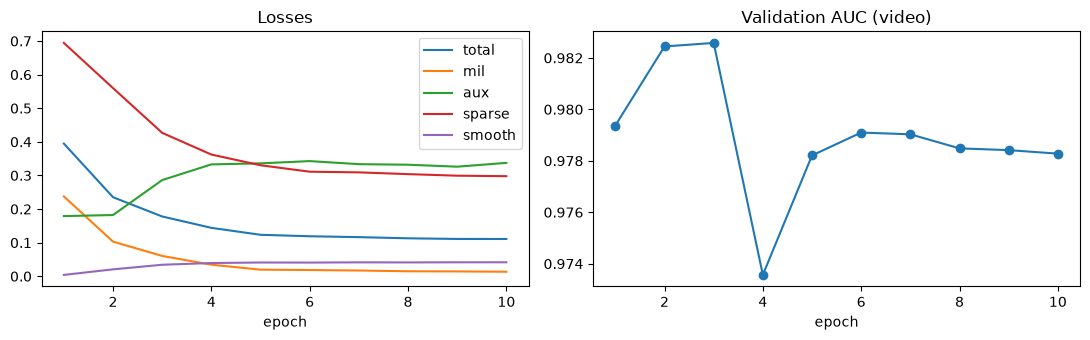

In [81]:
# 4.4 Train the model and plot curves
model, hist = train(USE_AUX, "modelo_binario")
model_no_aux = train(False, "modelo_binario_sin_aux")[0] if (TRAIN_WITHOUT_AUX and USE_AUX) else None

h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
_extra = [k for k, on in (("bottomk", USE_BOTTOMK), ("rank", USE_RANKING), ("uca_neg", UCA_NEGATIVES)) if on and k in h]
h.plot(x="epoch", y=["total", "mil", "aux", "sparse", "smooth"] + _extra, ax=ax[0], title="Losses")
if "val_proxy_auc" in h:
    h.plot(x="epoch", y=["val_auc", "val_proxy_auc"], ax=ax[1], title="Validation AUC (video and proxy frame)", marker="o")
else:
    h.plot(x="epoch", y="val_auc", ax=ax[1], title="Validation AUC (video)", marker="o", legend=False)
plt.tight_layout(); plt.savefig(WORK / "figuras/curvas_entrenamiento.png", dpi=120); plt.show()

## 5. Evaluación

In [82]:
# 5.1 Predictions on validation and test
TAB = table.set_index("video")
def predict_videos(m, videos):
    return {v: predict(m, x) for v in videos if (x := get_features(v, extract=False)) is not None}
PRED_VAL = predict_videos(model, table.video[(table.split == "val") & table.tiene_features])
PRED_TEST = predict_videos(model, table.video[(table.split == "test") & table.tiene_features])
print(f"Predictions: {len(PRED_VAL)} val · {len(PRED_TEST)} test")

Predictions: 242 val · 290 test


,auc,ap,auc_anomalous_only,auc_video
test,0.8305,0.2791,0.6585,0.9676


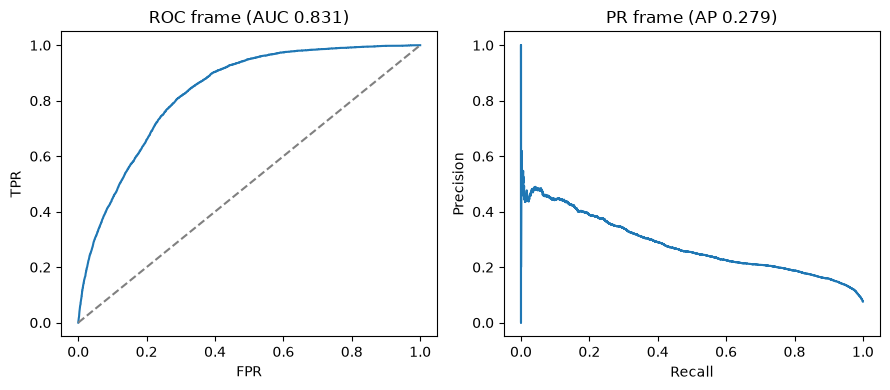

In [83]:
# 5.2 Frame-level AUC and AP (standard UCF-Crime metric)
def gt_mask(video, n_frag):
    g = np.zeros(n_frag * FRAG)
    for s, e in TAB.loc[video, "gt_frames"]:
        g[s:e + 1] = 1
    return g

def frame_arrays(pred, videos=None):
    videos = list(pred) if videos is None else videos
    S = np.concatenate([np.repeat(pred[v]["score"], FRAG) for v in videos])
    G = np.concatenate([gt_mask(v, len(pred[v]["score"])) for v in videos])
    return S, G

S, G = frame_arrays(PRED_TEST)
anom_test = [v for v in PRED_TEST if TAB.loc[v, "anomalo"]]
S_a, G_a = frame_arrays(PRED_TEST, anom_test)
met_frame = dict(auc=roc_auc_score(G, S), ap=average_precision_score(G, S),
                 auc_anomalous_only=roc_auc_score(G_a, S_a) if 0 < G_a.mean() < 1 else float("nan"),
                 auc_video=roc_auc_score([TAB.loc[v, "anomalo"] for v in PRED_TEST],
                                         [PRED_TEST[v]["video_score"] for v in PRED_TEST]))
display(pd.Series(met_frame).round(4).to_frame("test").T)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
fpr, tpr, _ = roc_curve(G, S); ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "--", c="gray")
ax[0].set(title=f"ROC frame (AUC {met_frame['auc']:.3f})", xlabel="FPR", ylabel="TPR")
pr, rc, _ = precision_recall_curve(G, S); ax[1].plot(rc, pr)
ax[1].set(title=f"PR frame (AP {met_frame['ap']:.3f})", xlabel="Recall", ylabel="Precision")
plt.tight_layout(); plt.savefig(WORK / "figuras/roc_pr_frame.png", dpi=120); plt.show()
RESULTS["frame"] = met_frame; save_results()

**Nota sobre el post-procesado.** `MERGE_GAP_SEC` y `MIN_EVENT_SEC` (celda 1.5) controlan cuánto se fragmentan los intervalos detectados. Con los valores por defecto (2 s y 1 s) el modelo produce muchos más intervalos que el ground truth; se sugiere probar `MERGE_GAP_SEC` entre 5 y 10 s y `MIN_EVENT_SEC` entre 2 y 3 s.

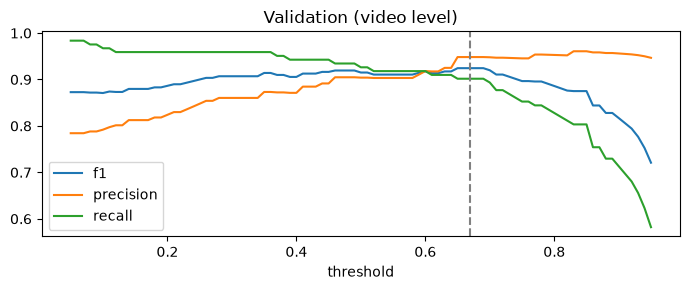

Threshold: 0.67


In [84]:
# 5.3 Post-processing and threshold calibration on validation
def postprocess(score, thr, fps):
    """Forward-backward EMA + hysteresis + minimum duration + gap merging. Returns per-fragment mask and intervals."""
    def _ema(x):
        out = np.zeros_like(x); e = x[0] if len(x) else 0.0
        for i, s in enumerate(x):
            e = EMA_ALPHA * s + (1 - EMA_ALPHA) * e; out[i] = e
        return out
    ema = (_ema(score) + _ema(score[::-1])[::-1]) / 2               # zero-phase (no time lag)
    on, mask = False, np.zeros(len(score), bool)
    for i, s in enumerate(ema):
        on = s > thr if not on else s > thr * OFF_RATIO
        mask[i] = on
    frag_sec = FRAG / fps
    iv, i = [], 0
    while i < len(mask):
        if mask[i]:
            j = i
            while j < len(mask) and mask[j]:
                j += 1
            iv.append([i, j]); i = j
        else:
            i += 1
    merged = []
    for s, e in iv:
        if merged and (s - merged[-1][1]) * frag_sec <= MERGE_GAP_SEC:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    merged = [(s, e) for s, e in merged if (e - s) * frag_sec >= MIN_EVENT_SEC]
    mask = np.zeros(len(score), bool)
    for s, e in merged:
        mask[s:e] = True
    return dict(ema=ema, mask=mask, intervals=merged)

def calibrate_threshold(pred):
    """Video-level F1 on validation: a video is flagged if it has at least one anomalous interval."""
    rows = []
    for thr in np.round(np.arange(0.05, 0.96, 0.01), 2):
        y = [TAB.loc[v, "anomalo"] for v in pred]
        p = [int(len(postprocess(pred[v]["score"], thr, TAB.loc[v, "fps"])["intervals"]) > 0) for v in pred]
        tp = sum(a and b for a, b in zip(y, p)); fp = sum((not a) and b for a, b in zip(y, p))
        fn = sum(a and not b for a, b in zip(y, p))
        f1 = 2 * tp / max(1, 2 * tp + fp + fn)
        rows.append(dict(threshold=thr, f1=f1, precision=tp / max(1, tp + fp), recall=tp / max(1, tp + fn)))
    return pd.DataFrame(rows)

CAL = calibrate_threshold(PRED_VAL)
_best = CAL.threshold[CAL.f1 >= CAL.f1.max() - 1e-9]          # middle of the best plateau
THR = float(THRESHOLD) if THRESHOLD is not None else float(_best.iloc[len(_best) // 2])
ax = CAL.plot(x="threshold", y=["f1", "precision", "recall"], figsize=(7, 3), title="Validation (video level)")
ax.axvline(THR, ls="--", c="gray"); plt.tight_layout(); plt.show()
print(f"Threshold: {THR:.2f}")
(WORK / "umbral.json").write_text(json.dumps({"threshold": THR, "ema_alpha": EMA_ALPHA, "off_ratio": OFF_RATIO,
                                               "min_event_sec": MIN_EVENT_SEC, "merge_gap_sec": MERGE_GAP_SEC}))
RESULTS["threshold"] = THR; save_results()

In [85]:
# 5.4 Segment detection on test: frame metrics at the threshold and interval matching
POST = {v: postprocess(PRED_TEST[v]["score"], THR, TAB.loc[v, "fps"]) for v in PRED_TEST}

# frame level at the threshold
P = np.concatenate([np.repeat(POST[v]["mask"], FRAG) for v in PRED_TEST]).astype(int)
tp, fp, fn = int((P & (G == 1)).sum()), int((P & (G == 0)).sum()), int(((1 - P) & (G == 1)).sum())
normal_test = [v for v in PRED_TEST if not TAB.loc[v, "anomalo"]]
far = float(np.mean(np.concatenate([POST[v]["mask"] for v in normal_test]))) if normal_test else float("nan")
met_thr = dict(precision=tp / max(1, tp + fp), recall=tp / max(1, tp + fn), f1=2 * tp / max(1, 2 * tp + fp + fn),
               false_alarm_rate_normal=far,
               normal_videos_with_alarm=float(np.mean([len(POST[v]["intervals"]) > 0 for v in normal_test])) if normal_test else float("nan"))

# interval level (temporal IoU with ground truth)
def iou_1d(a, b):
    inter = max(0, min(a[1], b[1]) - max(a[0], b[0]))
    return inter / max(1e-9, max(a[1], b[1]) - min(a[0], b[0]))

def match_intervals(post, thr_iou):
    tp = n_pred = n_gt = 0; best_ious = []
    for v, p in post.items():
        preds = [(s * FRAG, e * FRAG) for s, e in p["intervals"]]
        gts = [(s, e + 1) for s, e in TAB.loc[v, "gt_frames"]]
        n_pred += len(preds); n_gt += len(gts); used = set()
        for g in gts:
            ious = [(iou_1d(q, g), k) for k, q in enumerate(preds) if k not in used]
            best = max(ious, default=(0, -1))
            best_ious.append(best[0])
            if best[0] >= thr_iou:
                tp += 1; used.add(best[1])
    return dict(precision=tp / max(1, n_pred), recall=tp / max(1, n_gt), mean_best_iou=float(np.mean(best_ious)) if best_ious else float("nan"),
                predicted=n_pred, ground_truth=n_gt)

met_iv = pd.DataFrame({f"IoU ≥ {t}": match_intervals(POST, t) for t in IOU_THRESHOLDS}).T
display(pd.Series(met_thr).round(4).to_frame("test @ threshold").T)
display(met_iv.round(3))
RESULTS["at_threshold"] = met_thr; RESULTS["intervals"] = met_iv.to_dict("index"); save_results()

,precision,recall,f1,false_alarm_rate_normal,normal_videos_with_alarm
test @ threshold,0.2749,0.4474,0.3405,0.012,0.0533


,precision,recall,mean_best_iou,predicted,ground_truth
IoU ≥ 0.1,0.174,0.590,0.243,530.0,156.0
IoU ≥ 0.3,0.108,0.365,0.243,530.0,156.0
IoU ≥ 0.5,0.049,0.167,0.243,530.0,156.0


,videos,auc,ap
clase,,,
Fighting,5,0.817,0.077
Arrest,5,0.879,0.226
Shoplifting,21,0.886,0.188
Explosion,21,0.888,0.093
RoadAccidents,23,0.900,0.035
Shooting,23,0.903,0.134
Burglary,13,0.935,0.207
Arson,9,0.937,0.194
Abuse,2,0.939,0.006


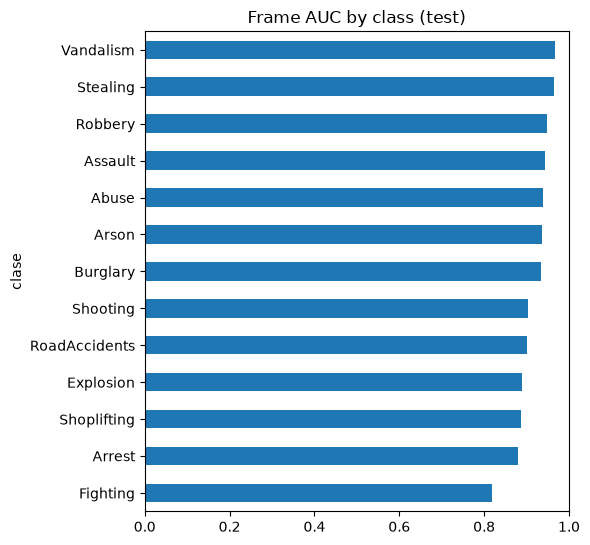

In [86]:
# 5.5 AUC by anomaly class (frames of each class vs normal test videos)
rows = []
for c, g in table[(table.split == "test") & (table.anomalo == 1)].groupby("clase_ucf"):
    vids = [v for v in g.video if v in PRED_TEST]
    if not vids or not normal_test:
        continue
    s, gg = frame_arrays(PRED_TEST, vids + normal_test)
    rows.append(dict(clase=c, videos=len(vids), auc=roc_auc_score(gg, s) if 0 < gg.mean() < 1 else np.nan,
                     ap=average_precision_score(gg, s) if gg.any() else np.nan))
BY_CLASS = pd.DataFrame(rows).set_index("clase").sort_values("auc")
display(BY_CLASS.round(3))
BY_CLASS.auc.plot.barh(figsize=(6, 0.35 * len(BY_CLASS) + 1), title="Frame AUC by class (test)"); plt.xlim(0, 1)
plt.tight_layout(); plt.savefig(WORK / "figuras/auc_por_clase.png", dpi=120); plt.show()
RESULTS["auc_by_class"] = BY_CLASS.to_dict("index"); save_results()

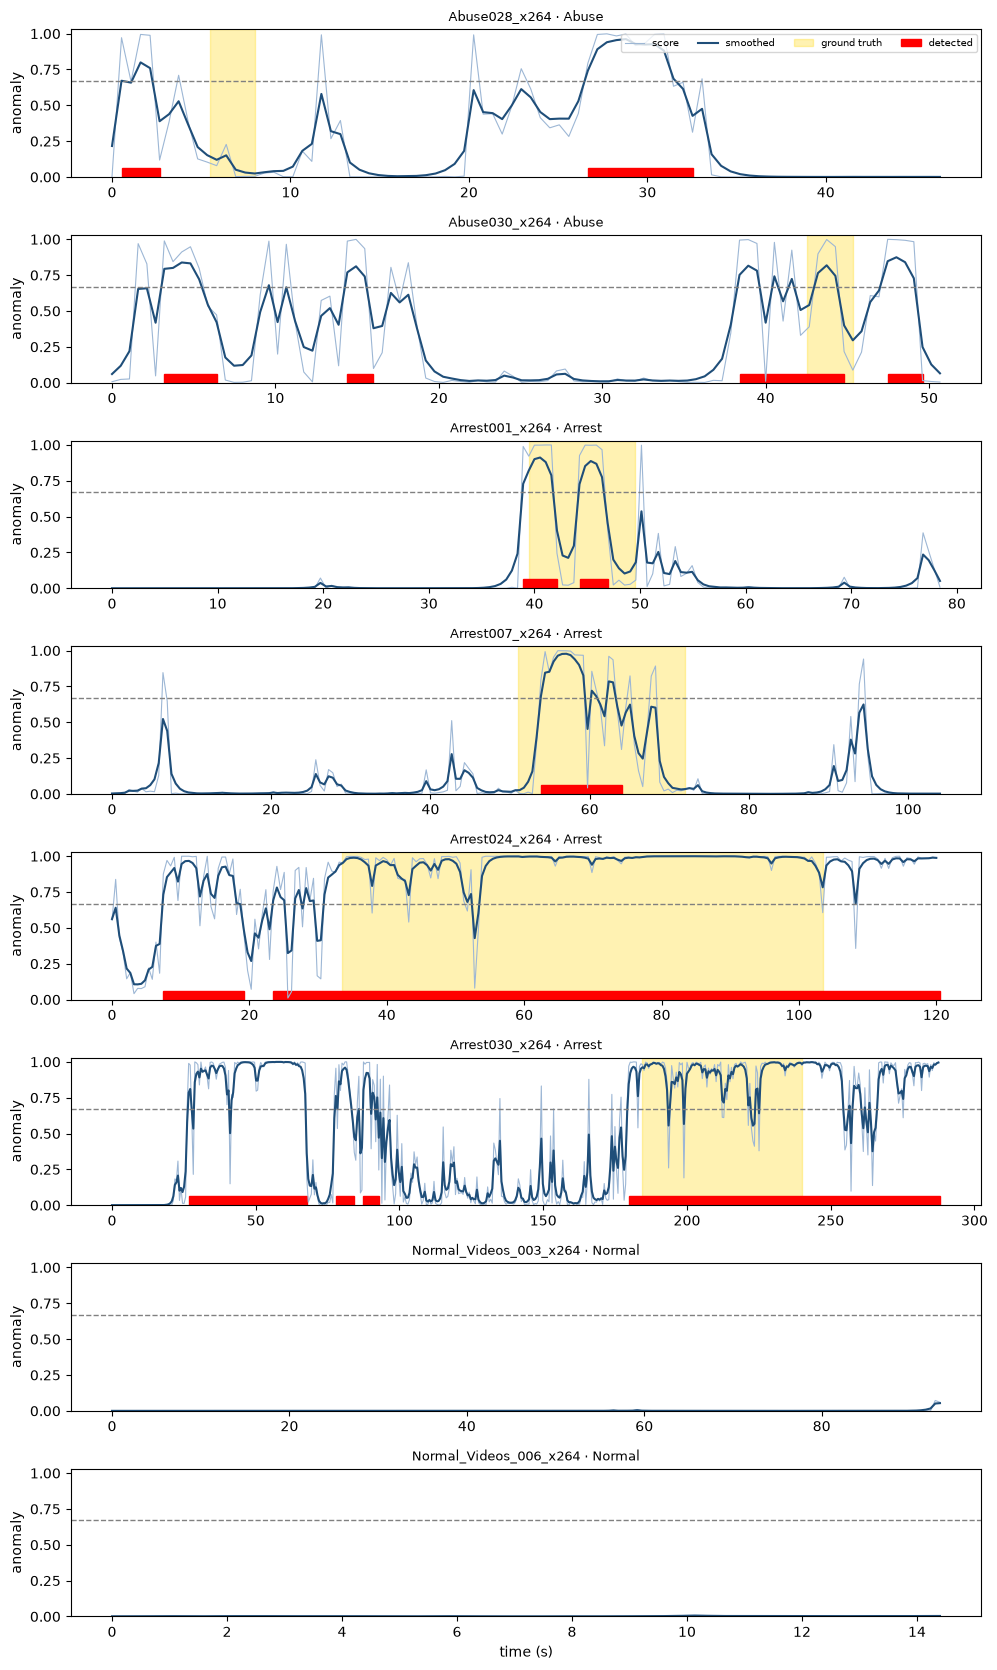

In [87]:
# 5.6 Anomaly curves per video (ground truth, threshold and detected intervals)
def plot_curve(ax, name, score, post, fps, gt_frames=(), thr=None):
    t = np.arange(len(score)) * FRAG / fps
    ax.plot(t, score, lw=0.8, c="#9DB7D5", label="score")
    ax.plot(t, post["ema"], lw=1.5, c="#1F4E79", label="smoothed")
    for k, (a, b) in enumerate(gt_frames):
        ax.axvspan(a / fps, b / fps, color="gold", alpha=0.3, label="ground truth" if k == 0 else None)
    for k, (s, e) in enumerate(post["intervals"]):
        ax.axvspan(s * FRAG / fps, e * FRAG / fps, ymin=0, ymax=0.06, color="red", label="detected" if k == 0 else None)
    if thr is not None:
        ax.axhline(thr, ls="--", c="gray", lw=1)
    ax.set_ylim(0, 1.03); ax.set_title(name, fontsize=9); ax.set_ylabel("anomaly")

_show = anom_test[:6] + normal_test[:2]
if _show:
    fig, axs = plt.subplots(len(_show), 1, figsize=(10, 2.1 * len(_show)), squeeze=False)
    for ax, v in zip(axs[:, 0], _show):
        plot_curve(ax, f"{v} · {TAB.loc[v, 'clase_ucf']}", PRED_TEST[v]["score"], POST[v], TAB.loc[v, "fps"],
                   TAB.loc[v, "gt_frames"], THR)
    axs[0, 0].legend(loc="upper right", fontsize=7, ncol=4); axs[-1, 0].set_xlabel("time (s)")
    plt.tight_layout(); plt.savefig(WORK / "figuras/curvas_por_video.png", dpi=120); plt.show()

In [88]:
# 5.7 Save predictions (per fragment and detected intervals)
rows, ivs = [], []
for v, p in PRED_TEST.items():
    fps = TAB.loc[v, "fps"]
    rows.append(pd.DataFrame({"video": v, "frag": np.arange(len(p["score"])), "t_ini_s": np.arange(len(p["score"])) * FRAG / fps,
                              "score": p["score"], "score_suave": POST[v]["ema"], "anomalo_pred": POST[v]["mask"].astype(int)}))
    ivs += [dict(video=v, clase_ucf=TAB.loc[v, "clase_ucf"], inicio_s=round(s * FRAG / fps, 2), fin_s=round(e * FRAG / fps, 2),
                 score_max=float(p["score"][s:e].max())) for s, e in POST[v]["intervals"]]
pd.concat(rows).to_csv(WORK / "predicciones/test_fragmentos.csv", index=False)
INTERVALS_TEST = pd.DataFrame(ivs, columns=["video", "clase_ucf", "inicio_s", "fin_s", "score_max"])
INTERVALS_TEST.to_csv(WORK / "predicciones/test_intervalos.csv", index=False)
display(INTERVALS_TEST.head(10))

,video,clase_ucf,inicio_s,fin_s,score_max
0,Abuse028_x264,Abuse,0.53,2.67,0.994551
1,Abuse028_x264,Abuse,26.67,32.53,0.998567
2,Abuse030_x264,Abuse,3.20,6.40,0.988787
3,Abuse030_x264,Abuse,14.40,16.00,0.999275
4,Abuse030_x264,Abuse,38.40,44.80,0.998299
5,Abuse030_x264,Abuse,47.47,49.60,0.999556
6,Arrest001_x264,Arrest,38.93,42.13,0.999645
7,Arrest001_x264,Arrest,44.27,46.93,0.998839
8,Arrest007_x264,Arrest,53.87,64.00,0.998915
9,Arrest024_x264,Arrest,7.47,19.20,0.999726


In [89]:
# 5.8 Ablation: with and without UCA auxiliary supervision (optional)
if model_no_aux is not None:
    _p = predict_videos(model_no_aux, list(PRED_TEST))
    _s, _g = frame_arrays(_p)
    ABL = pd.DataFrame([dict(model="with UCA aux", auc=met_frame["auc"], ap=met_frame["ap"]),
                        dict(model="without UCA aux", auc=roc_auc_score(_g, _s), ap=average_precision_score(_g, _s))]).set_index("model")
    display(ABL.round(4)); RESULTS["ablation_aux"] = ABL.to_dict("index"); save_results()
else:
    print("Set TRAIN_WITHOUT_AUX = True in 1.5 to run this comparison.")

Set TRAIN_WITHOUT_AUX = True in 1.5 to run this comparison.


## 6. Demo: video con los segmentos anómalos marcados

In [90]:
# 6.1 Rendering: banner, red border during anomalies and timeline
_FONT_PATH = matplotlib.font_manager.findfont("DejaVu Sans:bold")

def num(x):
    return f"{x:.2f}".replace(".", ",")

def timeline(w, h, score, post, thr, n_frames, gt_frames=()):
    """Bottom strip image (BGR): score curve, detected intervals and ground truth."""
    img = np.full((h, w, 3), 30, np.uint8)
    T = len(score)
    x_of = lambda frag: int(frag / max(T, 1) * (w - 1))
    for a, b in gt_frames:
        cv2.rectangle(img, (int(a / max(n_frames, 1) * (w - 1)), 0), (int(b / max(n_frames, 1) * (w - 1)), h - 1), (0, 200, 255), -1)
    img = cv2.addWeighted(img, 0.45, np.full_like(img, 30), 0.55, 0)
    for s, e in post["intervals"]:
        cv2.rectangle(img, (x_of(s), h - 7), (x_of(e), h - 1), (40, 40, 230), -1)
    pts = np.array([[x_of(i + 0.5), int((1 - post["ema"][i]) * (h - 12)) + 2] for i in range(T)], np.int32)
    if len(pts) > 1:
        cv2.polylines(img, [pts], False, (255, 255, 255), 1, cv2.LINE_AA)
    yt = int((1 - thr) * (h - 12)) + 2
    for x in range(0, w, 8):
        cv2.line(img, (x, yt), (min(x + 4, w - 1), yt), (150, 150, 150), 1)
    return img

def render_video(path, score, post, thr, out_path, gt_frames=()):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or DEFAULT_FPS
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    sh = max(40, h // 7)
    base = timeline(w, sh, score, post, thr, n, gt_frames)
    font = ImageFont.truetype(_FONT_PATH, max(12, h // 26))
    tmp = str(out_path) + ".tmp.mp4"
    vw = cv2.VideoWriter(tmp, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h + sh))
    f = 0
    while True:
        ok, im = cap.read()
        if not ok:
            break
        k = min(f // FRAG, len(score) - 1)
        anomalous = bool(post["mask"][k])
        if anomalous:
            cv2.rectangle(im, (0, 0), (w - 1, h - 1), (40, 40, 230), max(4, h // 60))
        pil = Image.fromarray(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); dr = ImageDraw.Draw(pil)
        txt = f"ANOMALÍA · {num(post['ema'][k])}" if anomalous else f"Normal · {num(post['ema'][k])}"
        tw = dr.textlength(txt, font=font)
        dr.rectangle([8, 8, 8 + tw + 14, 8 + font.size + 10], fill=(200, 30, 30) if anomalous else (40, 40, 40))
        dr.text((15, 12), txt, font=font, fill=(255, 255, 255))
        strip = base.copy(); x = int(f / max(n, 1) * (w - 1))
        cv2.line(strip, (x, 0), (x, sh - 1), (0, 255, 255), 2)
        vw.write(np.vstack([cv2.cvtColor(np.asarray(pil), cv2.COLOR_RGB2BGR), strip]))
        f += 1
    cap.release(); vw.release()
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", tmp, "-c:v", "libx264", "-pix_fmt", "yuv420p",
                    "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2", "-movflags", "+faststart", str(out_path)], check=True)
    os.remove(tmp)
    return out_path

In [91]:
# 6.2 Full analysis of one video
def analyze_video(path, show=True):
    name = Path(path).stem
    x = get_features(name, extract=False)
    if x is None:
        x = extract_video_features(path, name)           # video without VadCLIP features
    fps = video_info(path)[1]
    p = predict(model, x)
    post = postprocess(p["score"], THR, fps)
    gt = TAB.loc[name, "gt_frames"] if name in TAB.index else []
    out = render_video(path, p["score"], post, THR, WORK / f"demo/{name}_anomalia.mp4", gt)
    iv = pd.DataFrame([dict(inicio_s=round(s * FRAG / fps, 2), fin_s=round(e * FRAG / fps, 2),
                            score_max=round(float(p["score"][s:e].max()), 3)) for s, e in post["intervals"]],
                      columns=["inicio_s", "fin_s", "score_max"])
    iv.to_csv(WORK / f"demo/{name}_intervalos.csv", index=False)
    if show:
        fig, ax = plt.subplots(figsize=(10, 2.4))
        plot_curve(ax, name, p["score"], post, fps, gt, THR); ax.set_xlabel("time (s)"); ax.legend(fontsize=7, ncol=4)
        plt.tight_layout(); plt.savefig(WORK / f"demo/{name}_curva.png", dpi=120); plt.show()
        print(f"Video score: {num(p['video_score'])} · intervals detected: {len(iv)}")
        display(iv)
        display(Video(str(out), embed=True, width=720))
    return out, iv

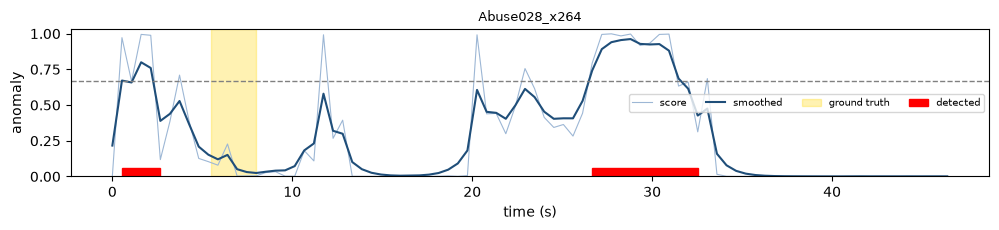

Video score: 1,00 · intervals detected: 2


,inicio_s,fin_s,score_max
0,0.53,2.67,0.995
1,26.67,32.53,0.999


/mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/binario/demo/Abuse028_x264_anomalia.mp4


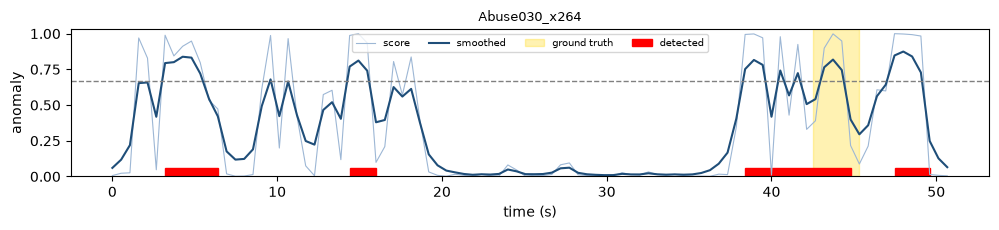

Video score: 1,00 · intervals detected: 4


,inicio_s,fin_s,score_max
0,3.20,6.4,0.989
1,14.40,16.0,0.999
2,38.40,44.8,0.998
3,47.47,49.6,1.000


/mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/binario/demo/Abuse030_x264_anomalia.mp4


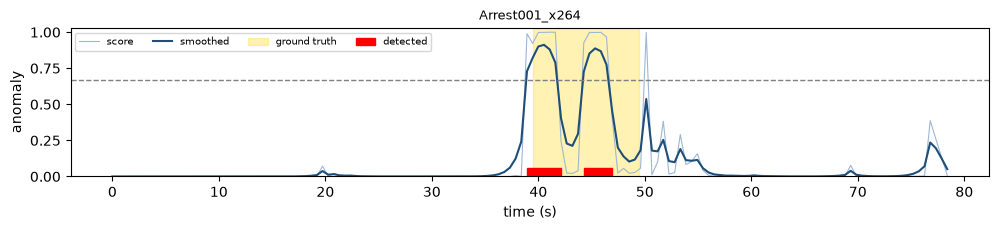

Video score: 0,99 · intervals detected: 2


,inicio_s,fin_s,score_max
0,38.93,42.13,1.000
1,44.27,46.93,0.999


/mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/binario/demo/Arrest001_x264_anomalia.mp4


In [92]:
# 6.3 Run the demo
_demo = DEMO_VIDEOS or [TAB.loc[v, "ruta_video"] for v in anom_test + normal_test[:1]
                        if isinstance(TAB.loc[v, "ruta_video"], str)][:3]
if not _demo:
    print("No videos found: add paths to DEMO_VIDEOS in cell 1.2.")
for path in _demo:
    print(analyze_video(path)[0])

## 8. Experimentos

Comparación de variantes para mejorar la **localización temporal** dentro de los videos anómalos. Cada configuración parte de la línea base (todos los switches apagados) y activa solo los indicados. Cada modelo se guarda con un nombre que incluye sus switches activos, así que con `LOAD_IF_EXISTS = True` se reutilizan sin mezclarse.

Métricas en el test oficial: AUC y AP por frame, AUC solo dentro de videos anómalos, AUC por video, F1 por frame con el umbral calibrado en validación (igual que en 5.3), precisión y recall de intervalos con IoU ≥ 0,3 y tasa de falsas alarmas en videos normales.

Se ejecuta solo con `RUN_EXPERIMENTS = True` (celda 1.5); entrena hasta un modelo por configuración.

In [93]:
# 8.1 Configurations and evaluation of one model
SWITCHES_OFF = dict(USE_BOTTOMK=False, USE_RANKING=False, CENTER_FEATURES="none", ADD_DIFF=False, ATTN_WINDOW=None,
                    UCA_NEGATIVES=False, TRAIN_WINDOWS=False, SELECT_BY="video_auc")
_ALL = dict(USE_BOTTOMK=True, USE_RANKING=True, CENTER_FEATURES="subtract", ATTN_WINDOW=8)
EXPERIMENTS = [
    ("baseline", {}),
    ("+bottomk", dict(USE_BOTTOMK=True)),
    ("+center subtract", dict(CENTER_FEATURES="subtract")),
    ("+window 8", dict(ATTN_WINDOW=8)),
    ("bottomk+center+window8", dict(USE_BOTTOMK=True, CENTER_FEATURES="subtract", ATTN_WINDOW=8)),
    ("bottomk+center+window8 · proxy selection", dict(USE_BOTTOMK=True, CENTER_FEATURES="subtract", ATTN_WINDOW=8,
                                                      SELECT_BY="proxy_frame_auc")),
    ("all + UCA negatives", dict(_ALL, UCA_NEGATIVES=True)),
    ("all + UCA negatives + train windows", dict(_ALL, UCA_NEGATIVES=True, TRAIN_WINDOWS=True)),
]

def evaluate_model(m):
    """Same metrics as 5.2-5.4 for one model (threshold calibrated on validation as in 5.3)."""
    pv, pt = predict_videos(m, list(PRED_VAL)), predict_videos(m, list(PRED_TEST))
    s, g = frame_arrays(pt)
    s_a, g_a = frame_arrays(pt, anom_test)
    cal = calibrate_threshold(pv)
    best = cal.threshold[cal.f1 >= cal.f1.max() - 1e-9]
    thr = float(THRESHOLD) if THRESHOLD is not None else float(best.iloc[len(best) // 2])
    post = {v: postprocess(pt[v]["score"], thr, TAB.loc[v, "fps"]) for v in pt}
    p = np.concatenate([np.repeat(post[v]["mask"], FRAG) for v in pt]).astype(int)
    tp, fp, fn = int((p & (g == 1)).sum()), int((p & (g == 0)).sum()), int(((1 - p) & (g == 1)).sum())
    iv = match_intervals(post, 0.3)
    return dict(frame_auc=roc_auc_score(g, s), ap=average_precision_score(g, s),
                auc_anomalous_only=roc_auc_score(g_a, s_a) if 0 < g_a.mean() < 1 else float("nan"),
                video_auc=roc_auc_score([TAB.loc[v, "anomalo"] for v in pt], [pt[v]["video_score"] for v in pt]),
                threshold=thr, frame_f1=2 * tp / max(1, 2 * tp + fp + fn),
                interval_precision_iou03=iv["precision"], interval_recall_iou03=iv["recall"],
                predicted_intervals=iv["predicted"], ground_truth_intervals=iv["ground_truth"],
                false_alarm_rate_normal=float(np.mean(np.concatenate([post[v]["mask"] for v in normal_test]))) if normal_test else float("nan"))

In [94]:
# 8.2 Train (or load) each configuration and compare
if RUN_EXPERIMENTS:
    _main = {k: globals()[k] for k in SWITCHES_OFF}
    rows = []
    try:
        for label, cfg in EXPERIMENTS:
            globals().update({**SWITCHES_OFF, **cfg})
            print(f"=== {label} · checkpoint modelo_binario{variant_tag()}.pt")
            set_seeds()
            m, _ = train(USE_AUX, "modelo_binario")
            rows.append(dict(config=label, checkpoint=f"modelo_binario{variant_tag()}", **evaluate_model(m)))
            del m
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
    finally:
        globals().update(_main)                       # later cells keep the main configuration
    EXP = pd.DataFrame(rows).set_index("config").sort_values("auc_anomalous_only", ascending=False)
    with pd.option_context("display.max_columns", None, "display.width", 200):
        display(EXP.drop(columns="checkpoint").round(4))
    EXP.to_csv(WORK / "experimentos.csv")
    RESULTS["experiments"] = EXP.to_dict("index"); save_results()

    _cols = ["auc_anomalous_only", "frame_auc", "ap", "frame_f1", "interval_precision_iou03", "interval_recall_iou03"]
    _order = EXP.index[::-1]                          # best configuration on top
    fig, axs = plt.subplots(1, len(_cols), figsize=(3 * len(_cols), 0.45 * len(EXP) + 1.2), sharey=True)
    for ax, col in zip(axs, _cols):
        ax.barh(_order, EXP.loc[_order, col], color="#1F4E79", height=0.6)
        if "baseline" in EXP.index:
            ax.axvline(EXP.loc["baseline", col], ls="--", c="gray", lw=1)
        ax.set_xlim(0, 1); ax.set_title(col, fontsize=9); ax.tick_params(labelsize=8)
        ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    fig.suptitle("Experiments on test (dashed line = baseline)", fontsize=10)
    plt.tight_layout(); plt.savefig(WORK / "figuras/experimentos.png", dpi=120); plt.show()
else:
    print("Set RUN_EXPERIMENTS = True in 1.5 to run the comparison.")

=== baseline · checkpoint modelo_binario.pt
Loaded /mnt/af724231-956c-44f8-ae04-79cc6b3e18d2/IA_2_Dataset/trabajo/binario/modelos/modelo_binario.pt
=== +bottomk · checkpoint modelo_binario_bk0.5x0.3.pt
Epoch  1 · loss 0.5089 · val AUC 0.9641 · val proxy frame AUC 0.9257
Epoch  2 · loss 0.2498 · val AUC 0.9728 · val proxy frame AUC 0.9506
Epoch  3 · loss 0.1945 · val AUC 0.9761 · val proxy frame AUC 0.9688
Epoch  4 · loss 0.1550 · val AUC 0.9740 · val proxy frame AUC 0.9818
Epoch  5 · loss 0.1318 · val AUC 0.9730 · val proxy frame AUC 0.9831
Epoch  6 · loss 0.1267 · val AUC 0.9747 · val proxy frame AUC 0.9853
Epoch  7 · loss 0.1250 · val AUC 0.9752 · val proxy frame AUC 0.9857
Epoch  8 · loss 0.1223 · val AUC 0.9753 · val proxy frame AUC 0.9864
Epoch  9 · loss 0.1190 · val AUC 0.9751 · val proxy frame AUC 0.9868
Epoch 10 · loss 0.1195 · val AUC 0.9748 · val proxy frame AUC 0.9865
=== +center subtract · checkpoint modelo_binario_csubtract.pt
Epoch  1 · loss 0.4580 · val AUC 0.9305 · val 

KeyboardInterrupt: 

## 9. Conclusiones

In [ ]:
# 9.1 Metrics summary
print(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float))

{
  "frame": {
    "auc": 0.8305047771564825,
    "ap": 0.2791476856801697,
    "auc_anomalous_only": 0.6585472027702348,
    "auc_video": 0.9676190476190476
  },
  "threshold": 0.67,
  "at_threshold": {
    "precision": 0.2748702926431153,
    "recall": 0.44741368062721654,
    "f1": 0.34053290361603494,
    "false_alarm_rate_normal": 0.011977083024645627,
    "normal_videos_with_alarm": 0.05333333333333334
  },
  "intervals": {
    "IoU ≥ 0.1": {
      "precision": 0.17358490566037735,
      "recall": 0.5897435897435898,
      "mean_best_iou": 0.24281305889494753,
      "predicted": 530.0,
      "ground_truth": 156.0
    },
    "IoU ≥ 0.3": {
      "precision": 0.10754716981132076,
      "recall": 0.36538461538461536,
      "mean_best_iou": 0.24281305889494753,
      "predicted": 530.0,
      "ground_truth": 156.0
    },
    "IoU ≥ 0.5": {
      "precision": 0.04905660377358491,
      "recall": 0.16666666666666666,
      "mean_best_iou": 0.24281305889494753,
      "predicted": 530.0,

**Conclusiones** (completar con los resultados):

- AUC y AP a nivel de frame en el test oficial (referencia: VadCLIP reporta 88,02 % de AUC en UCF-Crime).
- Calidad de la localización: precisión y recall de intervalos por IoU, tasa de falsas alarmas en videos normales.
- Clases donde el modelo funciona mejor y peor (tabla 5.5).
- Efecto de cada cambio de localización (tabla de la sección 8, ordenada por `auc_anomalous_only`).

**Limitaciones**

- Entrenamiento débilmente supervisado: solo se conoce la etiqueta del video completo, no el momento exacto.
- El umbral se calibra a nivel de video en validación; puede no ser óptimo para la localización.
- Las anotaciones UCA son ruidosas y el filtro por verbos es heurístico.

**Siguiente paso:** añadir una rama de clasificación para identificar el tipo de anomalía.